# Version 1 — The core idea: compensate a feature before dropping it

**Question.** If we must shrink a model's input, can we remove features *without
throwing away what they knew*, and keep every remaining feature in its original,
interpretable unit (which PCA cannot do)?

**Idea (SSFC — Standardized Sequential Feature Compensation).** Before dropping
feature $k$, fold the part of its information that is *linearly shared* with the
other features into them:

1. **Standardize** every feature with training statistics: $Z_i = (X_i-\mu_i)/\sigma_i$.
2. **Gate** the feature to remove with a smooth step: $p = \operatorname{sigmoid}(\beta Z_k)$.
3. **Inject** into each retained feature $j$:
   $$Z_j \leftarrow Z_j + \alpha \cdot p \cdot \operatorname{Cov}(Z_k, Z_j)$$
4. **Drop** feature $k$. Repeat for the next feature to remove (a *chain*).

$\alpha$ is the compensation strength. $\alpha = 0$ is exactly plain dropping.

This notebook uses **version 1 of the idea**: fixed $\alpha = 1$, $\beta = 1$, simple models
(Logistic Regression and Random Forest), and a handful of public datasets.

## The four results compared in every version

| Arm | What it does | Why it is there |
|---|---|---|
| **A. Naive** | all features, standardized | the baseline: what we would get if we kept everything |
| **B. PCA-guided drop** | PCA ranks features by impact; drop the *k* least impactful, **no compensation** | what a simple practitioner would do |
| **C. Compensate, then drop** | the **same** *k* features as B, but compensated into the rest first (**our idea**) | `C - B` isolates the effect of compensation |
| **D. PCA components** | classic PCA reduction to the same width (*d - k*) | standard reduction reference; loses per-feature meaning |

B and C remove exactly the same features, so any difference between them comes
from the compensation alone. Everything (PCA ranking, scaling, covariances) is
learned inside each cross-validation training fold, so nothing leaks from the test fold.

> **How to run.** `pip install -r requirements.txt`, open this file in VS Code
> (Python + Jupyter extensions), pick a Python kernel, *Run All*. Runtime ≈ 1–2 minutes.
> Pima / Ionosphere are downloaded once into `data/`; if you are offline they are skipped.

In [1]:
import sys, pathlib, warnings
warnings.filterwarnings("ignore")

# Make the `ssfc` package importable whether the notebook is opened from the
# repo root or from the notebooks/ folder (VS Code uses the notebook's folder).
ROOT = pathlib.Path.cwd()
if not (ROOT / "ssfc").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from ssfc import *          # SSFC, AutoAlphaSSFC, run_benchmark, paired_summary, plot_arms, ...

pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 30)
RESULTS = ROOT / "results"
RESULTS.mkdir(exist_ok=True)
print("repo root:", ROOT)

repo root: c:\research\ResearchAndGit


## 1. Load datasets
Two ship with scikit-learn; two are small public CSVs downloaded once.

In [2]:
datasets = load_many(["breast_cancer", "wine", "pima", "ionosphere"])

loaded breast_cancer  n=   569  d= 30  classes=2  | Breast Cancer Wisconsin (medical, binary)
loaded wine           n=   178  d= 13  classes=3  | Wine chemistry (3 classes)
loaded pima           n=   768  d=  8  classes=2  | Pima Indians Diabetes (8 features, binary)
loaded ionosphere     n=   351  d= 33  classes=2  | Ionosphere radar returns (34 features, binary)


## 2. A tiny worked example (5 samples × 8 features)

Real Pima Diabetes rows. We fit SSFC on the whole dataset (statistics only), remove the
**2 least impactful** features, and look at what the model would receive with and
without compensation. This is only for intuition; the real evaluation below fits
inside cross-validation folds.

In [3]:
X, y = datasets["pima"]
demo = SSFC(n_remove=2, selection="pca_low", compensate=True, alpha=1.0).fit(X)
plain = SSFC(n_remove=2, selection="pca_low", compensate=False).fit(X)

print("PCA impact of each feature (higher = takes part more in the dominant variance):")
print(pd.Series(demo.impact_, index=X.columns).sort_values(ascending=False).round(3).to_string())
print("\nRemoved (least impactful):", demo.removed_features_)
print("Kept:", demo.kept_features_)

first5 = X.head(5)
print("\n--- original rows (8 features) ---")
display(first5)
print("--- model input after PLAIN DROP (standardized, 6 features) ---")
display(pd.DataFrame(plain.transform(first5), columns=plain.kept_features_).round(2))
print("--- model input after COMPENSATE-THEN-DROP (6 features) ---")
display(pd.DataFrame(demo.transform(first5), columns=demo.kept_features_).round(2))

PCA impact of each feature (higher = takes part more in the dominant variance):
pedigree       0.132
bp             0.132
pregnancies    0.131
age            0.129
bmi            0.125
glucose        0.121
insulin        0.116
skin           0.115

Removed (least impactful): ['skin', 'insulin']
Kept: ['pregnancies', 'glucose', 'bp', 'bmi', 'pedigree', 'age']

--- original rows (8 features) ---


,pregnancies,glucose,bp,skin,insulin,bmi,pedigree,age
0,6.0,148.0,72.0,35.0,0.0,33.6,0.627,50.0
1,1.0,85.0,66.0,29.0,0.0,26.6,0.351,31.0
2,8.0,183.0,64.0,0.0,0.0,23.3,0.672,32.0
3,1.0,89.0,66.0,23.0,94.0,28.1,0.167,21.0
4,0.0,137.0,40.0,35.0,168.0,43.1,2.288,33.0


--- model input after PLAIN DROP (standardized, 6 features) ---


,pregnancies,glucose,bp,bmi,pedigree,age
0,0.64,0.85,0.15,0.20,0.47,1.43
1,-0.84,-1.12,-0.16,-0.68,-0.36,-0.19
2,1.23,1.94,-0.26,-1.10,0.60,-0.11
3,-0.84,-1.00,-0.16,-0.49,-0.92,-1.04
4,-1.14,0.50,-1.50,1.41,5.48,-0.02


--- model input after COMPENSATE-THEN-DROP (6 features) ---


,pregnancies,glucose,bp,bmi,pedigree,age
0,0.55,1.01,0.35,0.58,0.68,1.32
1,-0.93,-0.97,0.02,-0.34,-0.17,-0.29
2,1.19,2.06,-0.18,-0.93,0.71,-0.15
3,-0.94,-0.78,0.02,-0.13,-0.70,-1.14
4,-1.26,0.78,-1.26,1.88,5.77,-0.15


## 3. Which features are "low impact"? (PCA impact)

`pca_feature_impact` measures how much each feature takes part in the leading principal
components (weighted by their explained variance). **It never looks at the target**, so
"low impact" means "little share of the dominant variance", *not* "useless for prediction".

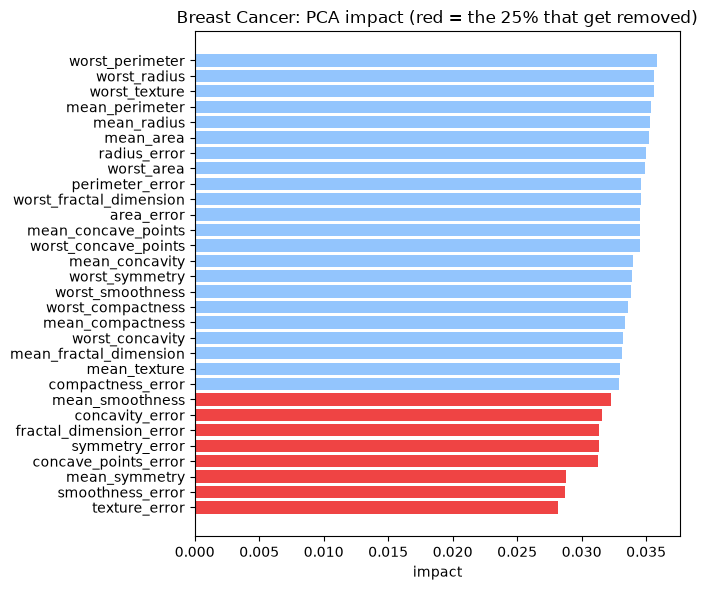

In [4]:
Xb, yb = datasets["breast_cancer"]
t = SSFC(n_remove=n_to_remove(Xb.shape[1], 0.25)).fit(Xb)
imp = pd.Series(t.impact_, index=Xb.columns).sort_values()
fig, ax = plt.subplots(figsize=(7, 6))
ax.barh(imp.index, imp.values, color=["#ef4444" if f in t.removed_features_ else "#93c5fd" for f in imp.index])
ax.set_title("Breast Cancer: PCA impact (red = the 25% that get removed)")
ax.set_xlabel("impact")
plt.tight_layout(); plt.show()

## 4. The four-arm comparison

* `FRAC_REMOVE = 0.25` → remove about a quarter of the features.
* Repeated stratified 5-fold cross-validation (identical folds for every arm).
* Metric: ROC-AUC (one-vs-rest for multi-class).

In [5]:
FRAC_REMOVE = 0.25
ALPHA, BETA = 1.0, 1.0            # version 1: fixed strength
N_SPLITS, N_REPEATS = 5, 2

models = {
    "LogReg": LogisticRegression(max_iter=2000),
    "RandForest": RandomForestClassifier(n_estimators=100, random_state=0, n_jobs=-1),
}

res_low, folds_low = run_benchmark(datasets, models, frac_remove=FRAC_REMOVE, alpha=ALPHA, beta=BETA,
                                   selection="pca_low", n_splits=N_SPLITS, n_repeats=N_REPEATS)
arm_table(res_low)

done breast_cancer LogReg                 k=8
done breast_cancer RandForest             k=8
done wine          LogReg                 k=3
done wine          RandForest             k=3
done pima          LogReg                 k=2
done pima          RandForest             k=2
done ionosphere    LogReg                 k=8
done ionosphere    RandForest             k=8


arm                      A_naive_all_features B_drop_no_compensation C_compensate_then_drop D_pca_components
dataset       model                                                                                         
breast_cancer LogReg          0.9948 ± 0.0050        0.9955 ± 0.0051        0.9947 ± 0.0056  0.9949 ± 0.0050
              RandForest      0.9893 ± 0.0081        0.9894 ± 0.0086        0.9898 ± 0.0060  0.9826 ± 0.0088
wine          LogReg          1.0000 ± 0.0000        0.9957 ± 0.0055        0.9997 ± 0.0010  0.9997 ± 0.0008
              RandForest      0.9994 ± 0.0014        0.9983 ± 0.0033        0.9992 ± 0.0019  0.9973 ± 0.0048
pima          LogReg          0.8297 ± 0.0286        0.8063 ± 0.0619        0.8081 ± 0.0524  0.8286 ± 0.0257
              RandForest      0.8223 ± 0.0278        0.8049 ± 0.0617        0.8111 ± 0.0454  0.8038 ± 0.0272
ionosphere    LogReg          0.9012 ± 0.0504        0.9095 ± 0.0365        0.9138 ± 0.0383  0.9173 ± 0.0459
              RandForest      0.9785 ± 0.0155        0.9760 ± 0.0166        0.9732 ± 0.0165  0.9777 ± 0.0166

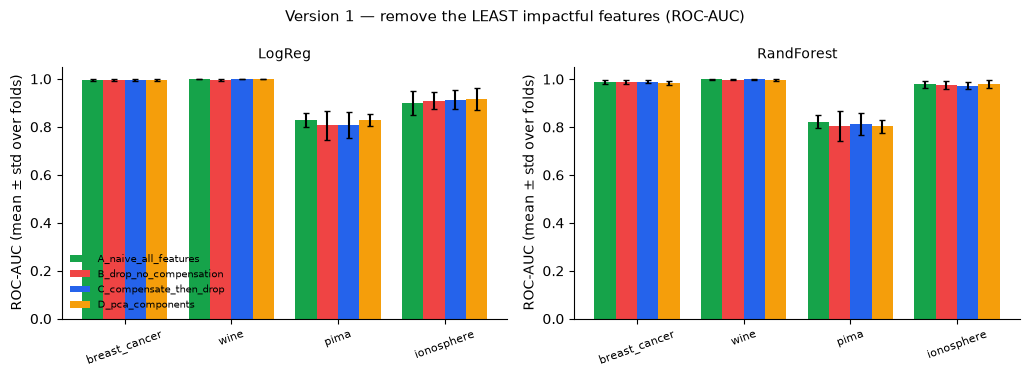

In [6]:
plot_arms(res_low, title="Version 1 — remove the LEAST impactful features (ROC-AUC)")
plt.show()

### Paired summary: does compensation (C) beat plain dropping (B)?
`comp_minus_drop` is the mean paired difference over folds, `se` its standard error
(folds overlap, so treat `se` as a rough guide, not a formal test).

In [7]:
sum_low = paired_summary(res_low, folds_low)
display(sum_low.round(4))
vc = verdict_counts(sum_low)
print(f"Compensation vs plain drop over {vc['total']} dataset×model cases:  "
      f"better (> 1 se): {vc['better']}   within noise: {vc['within_noise']}   worse (> 1 se): {vc['worse']}")

,dataset,model,d,k_removed,auc_naive,auc_drop,auc_comp,auc_pca,comp_minus_drop,se,comp_wins_folds
0,breast_cancer,LogReg,30,8,0.9948,0.9955,0.9947,0.9949,-0.0008,0.0002,0.0
1,breast_cancer,RandForest,30,8,0.9893,0.9894,0.9898,0.9826,0.0004,0.0018,0.4
2,wine,LogReg,13,3,1.0000,0.9957,0.9997,0.9997,0.0040,0.0016,0.6
3,wine,RandForest,13,3,0.9994,0.9983,0.9992,0.9973,0.0008,0.0006,0.2
4,pima,LogReg,8,2,0.8297,0.8063,0.8081,0.8286,0.0018,0.0038,0.4
5,pima,RandForest,8,2,0.8223,0.8049,0.8111,0.8038,0.0062,0.0077,0.6
6,ionosphere,LogReg,33,8,0.9012,0.9095,0.9138,0.9173,0.0043,0.0017,0.8
7,ionosphere,RandForest,33,8,0.9785,0.9760,0.9732,0.9777,-0.0028,0.0054,0.5


Compensation vs plain drop over 8 dataset×model cases:  better (> 1 se): 3   within noise: 4   worse (> 1 se): 1


## 5. Stress test: remove the MOST impactful features (by PCA)

Removing low-impact features usually costs very little, so there is little for compensation
to recover. Here we remove the *highest*-impact features to create a bigger gap.

arm                      A_naive_all_features B_drop_no_compensation C_compensate_then_drop D_pca_components
dataset       model                                                                                         
breast_cancer LogReg          0.9948 ± 0.0050        0.9917 ± 0.0073        0.9933 ± 0.0063  0.9949 ± 0.0050
              RandForest      0.9893 ± 0.0081        0.9910 ± 0.0048        0.9892 ± 0.0087  0.9826 ± 0.0088
wine          LogReg          1.0000 ± 0.0000        1.0000 ± 0.0000        1.0000 ± 0.0000  0.9997 ± 0.0008
              RandForest      0.9994 ± 0.0014        0.9994 ± 0.0014        0.9977 ± 0.0026  0.9973 ± 0.0048
pima          LogReg          0.8297 ± 0.0286        0.8214 ± 0.0328        0.8231 ± 0.0323  0.8286 ± 0.0257
              RandForest      0.8223 ± 0.0278        0.8113 ± 0.0286        0.8183 ± 0.0280  0.8038 ± 0.0272
ionosphere    LogReg          0.9012 ± 0.0504        0.8616 ± 0.0566        0.8765 ± 0.0560  0.9173 ± 0.0459
              RandForest      0.9785 ± 0.0155        0.9773 ± 0.0148        0.9715 ± 0.0173  0.9777 ± 0.0166

Compensation vs plain drop (most impactful removed): better 3, within noise 3, worse 2 of 8


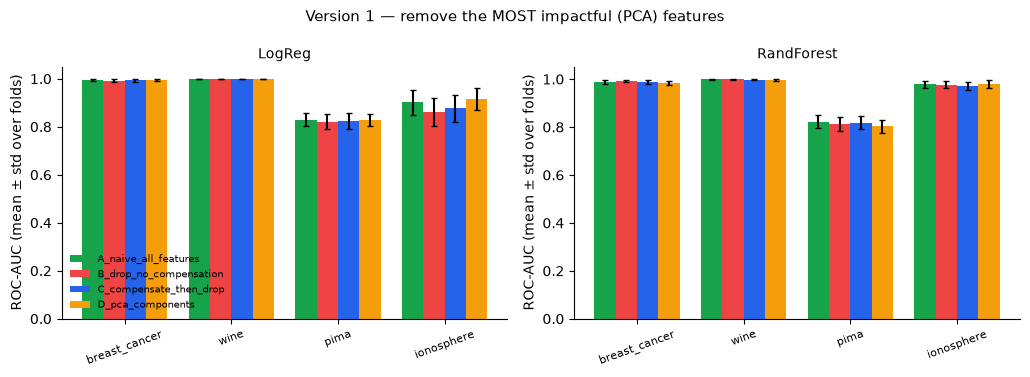

In [8]:
res_high, folds_high = run_benchmark(datasets, models, frac_remove=FRAC_REMOVE, alpha=ALPHA, beta=BETA,
                                     selection="pca_high", n_splits=N_SPLITS, n_repeats=N_REPEATS, verbose=False)
display(arm_table(res_high))
sum_high = paired_summary(res_high, folds_high)
vc = verdict_counts(sum_high)
print(f"Compensation vs plain drop (most impactful removed): better {vc['better']}, "
      f"within noise {vc['within_noise']}, worse {vc['worse']} of {vc['total']}")
plot_arms(res_high, title="Version 1 — remove the MOST impactful (PCA) features"); plt.show()

## 6. Stress test on features that truly matter (Pima: glucose, BMI, pedigree)

PCA impact is unsupervised, so it does not find the features the *target* depends on. In
earlier experiments (see `docs/research_log.md`) removing Pima's `glucose`, `bmi` and `pedigree`
caused a large performance drop, which is where compensation had the most room to help.
Here we remove exactly those three explicitly (`remove_idx`).

In [9]:
Xp, yp = datasets["pima"]
idx = [list(Xp.columns).index(c) for c in ["glucose", "bmi", "pedigree"]]
rows = []
for mname, model in models.items():
    table, folds = run_comparison(Xp, yp, model, n_remove=3, remove_idx=idx, alpha=ALPHA, beta=BETA,
                                  n_splits=N_SPLITS, n_repeats=N_REPEATS)
    table.insert(0, "model", mname); rows.append(table)
pima_stress = pd.concat(rows)
display(pima_stress[["model", "arm", "auc_mean", "auc_std", "n_features_used"]].round(4))

,model,arm,auc_mean,auc_std,n_features_used
0,LogReg,A_naive_all_features,0.8297,0.0286,8
1,LogReg,B_drop_no_compensation,0.6720,0.0310,5
2,LogReg,C_compensate_then_drop,0.6992,0.0310,5
3,LogReg,D_pca_components,0.7986,0.0320,5
0,RandForest,A_naive_all_features,0.8223,0.0278,8
1,RandForest,B_drop_no_compensation,0.7059,0.0314,5
2,RandForest,C_compensate_then_drop,0.7820,0.0272,5
3,RandForest,D_pca_components,0.7798,0.0280,5


In [10]:
out = pd.concat([res_low.assign(experiment="remove_least_impactful"),
                 res_high.assign(experiment="remove_most_impactful")])
out.to_csv(RESULTS / "v1_results.csv", index=False)
pima_stress.to_csv(RESULTS / "v1_pima_stress.csv", index=False)
print("saved results/v1_results.csv and results/v1_pima_stress.csv")

saved results/v1_results.csv and results/v1_pima_stress.csv


## 7. How to read these results (and caveats)

* **C vs B** is the fair test of compensation: same features removed, same width.
* **A** (all features) is the usual ceiling; **D** is the standard PCA alternative that gives up
  interpretability.
* When the dropped features carry little signal, A, B, C and D are all close and differences
  sit inside the noise. That is expected, not a bug.
* Version 1 uses a **fixed** $\alpha = 1$. It can help or hurt depending on the dataset, which is
  exactly what versions 2–4 investigate (other models, distance-based models, and a
  data-driven $\alpha$ with a safety guarantee).
* Results come from small public datasets and a few CV repeats; do not read tiny differences as
  conclusions.

**Next:** `v2_other_models.ipynb`.